In [3]:
import os
import json
import string
import numpy as np
import matplotlib.pyplot as plt

import keras
from keras.models import Sequential
from keras.layers import Input, Embedding, LSTM, Dense, Dropout
from keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.model_selection import train_test_split

os.makedirs("artifacts", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

In [4]:
DATASET_PATH = r"C:\Users\bilal\Downloads\The Complete Works of William Shakespeare by William Shakespeare.txt"
MAX_CHARS = 300000

# 1. Load text from my system
with open(DATASET_PATH, "r", encoding="utf-8") as f:
    text = f.read()

# 2. Strip Project Gutenberg boilerplate header
start_token = "*** START OF THE PROJECT GUTENBERG"
start_idx = text.find(start_token)
if start_idx != -1:
    text = text[start_idx + len(start_token):]

# 3. Normalize to lowercase and take a subset for efficient training
text = text[:MAX_CHARS].lower()

# 4. Remove punctuation while preserving spaces and line breaks
allowed_chars = set(string.ascii_lowercase + " \n")
cleaned_text = "".join([c for c in text if c in allowed_chars])

# 5. Build vocabulary mapping
chars = sorted(list(set(cleaned_text)))
char_to_idx = {ch: i for i, ch in enumerate(chars)}
idx_to_char = {i: ch for i, ch in enumerate(chars)}
vocab_size = len(chars)

# Persist vocab mappings
with open("artifacts/char_to_idx.json", "w", encoding="utf-8") as f:
    json.dump(char_to_idx, f)
with open("artifacts/idx_to_char.json", "w", encoding="utf-8") as f:
    json.dump({str(k): v for k, v in idx_to_char.items()}, f)

print(f"Total cleaned characters: {len(cleaned_text)}")
print(f"Vocabulary size: {vocab_size} unique characters")
print(f"Sample characters in vocab: {chars[:15]}...")

Total cleaned characters: 286024
Vocabulary size: 28 unique characters
Sample characters in vocab: ['\n', ' ', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm']...


In [5]:
SEQ_LENGTH = 50
STEP = 3

sentences = []
next_chars = []

for i in range(0, len(cleaned_text) - SEQ_LENGTH, STEP):
    sentences.append(cleaned_text[i : i + SEQ_LENGTH])
    next_chars.append(cleaned_text[i + SEQ_LENGTH])

num_samples = len(sentences)
print(f"Generated input-output sequence pairs: {num_samples}")

# Vectorize into numpy arrays
X = np.zeros((num_samples, SEQ_LENGTH), dtype=np.int32)
y = np.zeros((num_samples, vocab_size), dtype=np.float32)

for i, sentence in enumerate(sentences):
    for t, char in enumerate(sentence):
        X[i, t] = char_to_idx[char]
    y[i, char_to_idx[next_chars[i]]] = 1.0 
# Train-Validation split
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.1, random_state=42, shuffle=True
)

print(f"Train shapes -> X: {X_train.shape}, y: {y_train.shape}")
print(f"Val shapes   -> X: {X_val.shape}, y: {y_val.shape}")

Generated input-output sequence pairs: 95325
Train shapes -> X: (85792, 50), y: (85792, 28)
Val shapes   -> X: (9533, 50), y: (9533, 28)


In [6]:
EMBEDDING_DIM = 64
LSTM_UNITS = 128

def build_model(vocab_size, seq_length, embedding_dim=64, lstm_units=128):
    model = Sequential([
        Input(shape=(seq_length,)),
        Embedding(input_dim=vocab_size, output_dim=embedding_dim),
        LSTM(lstm_units, return_sequences=True),
        Dropout(0.2),
        LSTM(lstm_units),
        Dropout(0.2),
        Dense(vocab_size, activation="softmax")
    ])

    optimizer = keras.optimizers.Adam(learning_rate=0.002)
    model.compile(
        loss="categorical_crossentropy",
        optimizer=optimizer,
        metrics=["accuracy"]
    )
    return model

model = build_model(vocab_size, SEQ_LENGTH, EMBEDDING_DIM, LSTM_UNITS)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 64)         │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 50, 128)        │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 28)             │         3,612 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,804 (921.11 KB)

 Trainable params: 235,804 (921.11 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
BATCH_SIZE = 128
EPOCHS = 12

checkpoint_path = "artifacts/best_lstm_model.keras"

callbacks = [
    EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
    ModelCheckpoint(checkpoint_path, monitor="val_loss", save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1)
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/12
671/671 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - accuracy: 0.2904 - loss: 2.4085
Epoch 1: val_loss improved from None to 2.00636, saving model to artifacts/best_lstm_model.keras

Epoch 1: finished saving model to artifacts/best_lstm_model.keras
671/671 ━━━━━━━━━━━━━━━━━━━━ 123s 175ms/step - accuracy: 0.2904 - loss: 2.4085 - val_accuracy: 0.3860 - val_loss: 2.0064 - learning_rate: 0.0020
Epoch 2/12
671/671 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step - accuracy: 0.4192 - loss: 1.9187
Epoch 2: val_loss improved from 2.00636 to 1.79173, saving model to artifacts/best_lstm_model.keras

Epoch 2: finished saving model to artifacts/best_lstm_model.keras
671/671 ━━━━━━━━━━━━━━━━━━━━ 145s 179ms/step - accuracy: 0.4192 - loss: 1.9187 - val_accuracy: 0.4474 - val_loss: 1.7917 - learning_rate: 0.0020
Epoch 3/12
670/671 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - accuracy: 0.4603 - loss: 1.7625
Epoch 3: val_loss improved from 1.79173 to 1.70266, saving model to artifacts/best_lstm_model.keras

Epoch 3: finis

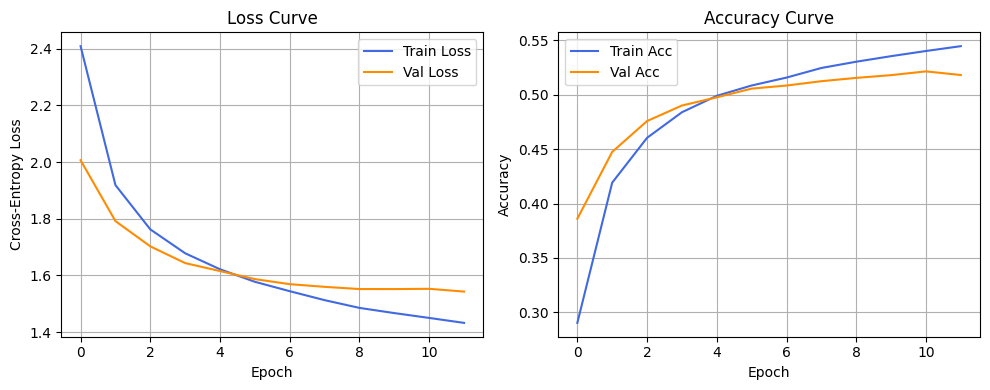

In [8]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Train Loss", color="royalblue")
plt.plot(history.history["val_loss"], label="Val Loss", color="darkorange")
plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Train Acc", color="royalblue")
plt.plot(history.history["val_accuracy"], label="Val Acc", color="darkorange")
plt.title("Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("outputs/training_curves.png", dpi=300)
plt.show()

In [9]:
def sample_with_temperature(preds, temperature=0.5):
    preds = np.asarray(preds).astype("float64")
    preds = np.log(preds + 1e-8) / max(temperature, 1e-5)
    exp_preds = np.exp(preds)
    probas = exp_preds / np.sum(exp_preds)
    return np.random.choice(len(probas), p=probas)


def generate_text(model, seed_text, char_to_idx, idx_to_char, seq_length=50, gen_length=250, temperature=0.5):
    seed = seed_text.lower()[-seq_length:]
    if len(seed) < seq_length:
        seed = seed.rjust(seq_length)

    current_seq = seed
    generated = ""

    for _ in range(gen_length):
        x_pred = np.zeros((1, seq_length), dtype=np.int32)
        for t, char in enumerate(current_seq):
            x_pred[0, t] = char_to_idx.get(char, 0)

        preds = model.predict(x_pred, verbose=0)[0]
        next_idx = sample_with_temperature(preds, temperature)
        next_char = idx_to_char[next_idx]

        generated += next_char
        current_seq = current_seq[1:] + next_char

    return generated

In [10]:
seeds = [
    "to be or not to be that is the question",
    "shall i compare thee to a summers day",
    "friends romans countrymen lend me your ears"
]

temperatures = [0.2, 0.5, 0.8]
deliverable_path = "outputs/sample_generations.txt"

with open(deliverable_path, "w", encoding="utf-8") as out:
    for seed in seeds:
        header = f"\n{'='*70}\nSEED: '{seed}'\n{'='*70}\n"
        print(header)
        out.write(header)

        for temp in temperatures:
            gen = generate_text(
                model=model,
                seed_text=seed,
                char_to_idx=char_to_idx,
                idx_to_char=idx_to_char,
                seq_length=SEQ_LENGTH,
                gen_length=200,
                temperature=temp
            )
            block = f"--- Temperature: {temp} ---\n{seed}{gen}\n\n"
            print(block)
            out.write(block)

print(f"\nGenerations successfully saved to: {deliverable_path}")


SEED: 'to be or not to be that is the question'

--- Temperature: 0.2 ---
to be or not to be that is the question some with the reasons are my dear he have the will the world the some of stand and will the stare i have the store of the dear in the starge of the will the still with the son and he have not so stee


--- Temperature: 0.5 ---
to be or not to be that is the question of the from the place


                                        

the rase and dear i will the world not so see i may and the braster with the means are to the whom my tray in the oor thou art to som


--- Temperature: 0.8 ---
to be or not to be that is the question of with the sond
in not that doth live
the kingg and countloor and bear my beauty your good of the world to against sir you do forget no set of he my done
but my love me wibeth who have to the praise



SEED: 'shall i compare thee to a summers day'

--- Temperature: 0.2 ---
shall i compare thee to a summers day

countess
i will be the praise to the 